In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import os, glob

In [2]:
import matplotlib as mpl
import matplotlib.font_manager as fm

FONT_DIR = os.path.expanduser("~/fonts/SourceSans3")

for f in glob.glob(os.path.join(FONT_DIR, "*.ttf")):
    fm.fontManager.addfont(f)

available = {f.name for f in fm.fontManager.ttflist}
FAMILY = next((n for n in ("Source Sans 3", "Source Sans Pro") if n in available), None)
if FAMILY is None:
    raise RuntimeError(f"Source Sans not found. Check FONT_DIR: {FONT_DIR}")

W = 418.25372 / 72.27   # \textwidth in inches (~5.787)
W_HALF = 0.48 * W       # two panels side by side

mpl.rcParams.update({
    # --- Text / fonts ---
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": [FAMILY],
    "mathtext.fontset": "custom",
    "mathtext.rm": FAMILY,
    "mathtext.it": f"{FAMILY}:italic",
    "mathtext.bf": f"{FAMILY}:bold",
    "mathtext.sf": FAMILY,
    "mathtext.default": "it",
    "mathtext.fallback": "cm",     
    "axes.unicode_minus": True,    

    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.titlesize": 10,

    "axes.linewidth": 0.8,
    "lines.linewidth": 1.3,
    "lines.markersize": 4,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,
    "xtick.minor.size": 2,
    "ytick.minor.size": 2,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.4,

    "legend.frameon": False,
    "legend.handlelength": 1.5,

    "figure.figsize": (W, W),
    "figure.constrained_layout.use": True,
    "savefig.dpi": 300,             
    "savefig.format": "pdf",
    "pdf.fonttype": 42,    
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

In [4]:
run = '2024/oper_08'

In [5]:
path = '/jetfs/scratch/psplechtna/thesisdata/oper/'


In [35]:
data = xr.open_dataset(path+run+'_temporal_evol.nc')
reference = xr.open_dataset(path+'1991-2020/1991_temporal_evol.nc')

In [36]:
reference_mean = reference.mean(dim='release_time')
reference_std = reference.std(dim='release_time')

In [37]:
release = 10
data=data.isel(release_time=release)

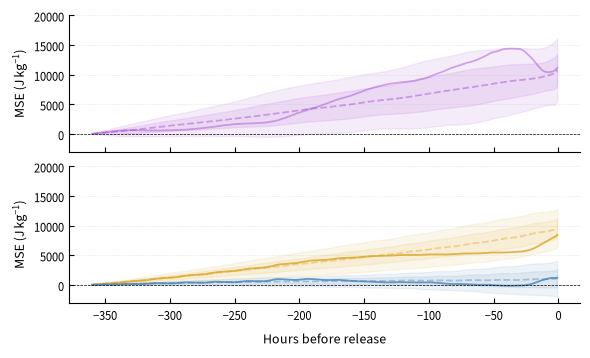

In [ ]:
xes = data.lag

fig, ax = plt.subplots(2, 1, figsize=(W, 0.6*W), sharex=True)


lh_flux, = ax[0].plot(xes, data.advection, color='darkorchid',
                   linestyle='-', alpha=0.4, label='Advection')
lh_flux_m, = ax[0].plot(xes, reference_mean.advection, color='darkorchid',
                   linestyle='--', alpha=0.4, label='Advection Mean')
ax[0].fill_between(xes, reference_mean.advection - reference_std.advection,
                reference_mean.advection + reference_std.advection, color='darkorchid', alpha=0.1)
ax[0].fill_between(xes, reference_mean.advection - 2*reference_std.advection,
                reference_mean.advection + 2*reference_std.advection, color='darkorchid', alpha=0.09)

lh_flux, = ax[1].plot(xes, data.flux_lh, color='goldenrod',
                   linestyle='-', alpha=0.8, label='LH')
lh_flux_m, = ax[1].plot(xes, reference_mean.flux_lh, color='goldenrod',
                   linestyle='--', alpha=0.4, label='LH Mean')
ax[1].fill_between(xes, reference_mean.flux_lh - reference_std.flux_lh,
                reference_mean.flux_lh + reference_std.flux_lh, color='goldenrod', alpha=0.1)
ax[1].fill_between(xes, reference_mean.flux_lh - 2*reference_std.flux_lh,
                reference_mean.flux_lh + 2*reference_std.flux_lh, color='goldenrod', alpha=0.09)

lh_flux, = ax[1].plot(xes, data.flux_sh, color='steelblue',
                   linestyle='-', alpha=0.8, label='SH')
lh_flux_m, = ax[1].plot(xes, reference_mean.flux_sh, color='steelblue',
                   linestyle='--', alpha=0.4, label='SH Mean')
ax[1].fill_between(xes, reference_mean.flux_sh - reference_std.flux_sh,
                reference_mean.flux_sh + reference_std.flux_sh, color='steelblue', alpha=0.1)
ax[1].fill_between(xes, reference_mean.flux_sh - 2*reference_std.flux_sh,
                reference_mean.flux_sh + 2*reference_std.flux_sh, color='steelblue', alpha=0.09)

ax[1].set_xlabel('Hours before release')

for axs in ax:
    axs.grid(linestyle=':', alpha=0.5, axis='y')
    axs.axhline(0, color='k', linestyle='--', linewidth=0.5)
    axs.set_ylim(-3000, 20000)
    axs.set_ylabel('MSE ($\mathrm{J\,kg^{-1}}$)')

#fig.savefig('plots/temporal_evol.pdf')